# Módulo 24 · Práctica: formular y resolver problemas de optimización

Este cuaderno implementa, paso a paso, los **casos de estudio** de los apuntes del módulo 24. En cada parte se parte de un problema real descrito con datos (sintéticos pero con unidades realistas), se escribe el modelo matemático, se elige el método y se comprueba el resultado por un segundo camino (enumeración, condiciones de optimalidad o simulación).

| Parte | Caso de los apuntes | Qué se hace |
| --- | --- | --- |
| 0 | — | Preparación y bibliotecas |
| 1 | Tema 1 · fábrica de piensos | Formular un PL de dos variables, resolverlo por vértices y leer los precios sombra |
| 2 | Tema 2 · cervecera | Plan de producción semanal MILP (inventario, preparaciones, lote mínimo), relajación, *gap* y ramificación y acotación |
| 3 | Tema 3 · reparto y taller | Rutas con ventanas horarias (VRPTW) y taller *job-shop* con CP-SAT, verificados de forma exacta |
| 4 | Tema 4 · despacho económico | Condiciones KKT, coste incremental igual y CVXPY |
| 5 | Tema 5 · distribución en planta | Recocido simulado, frente de Pareto y un NSGA-II mínimo |
| 6 | Tema 6 · cerveza fresca | Predecir la demanda y optimizar: media, cuantil, SAA y decisión robusta |
| 7 | — | Retos |

**Cómo usar el cuaderno.** Las celdas marcadas con `# TU CÓDIGO` son los ejercicios; la celda siguiente comprueba el resultado con `assert`. La versión distribuida trae esas celdas **rellenas con la solución de referencia**, para que el cuaderno se ejecute de principio a fin y sus resultados coincidan con los de los apuntes. Para practicar, borra el contenido entre `# --- solución de referencia ---` y `# --- fin ---`, escribe tu versión y ejecuta la comprobación. Al final hay comentarios a cada solución.

Todos los datos se generan aquí con semillas fijas; no se descarga nada. Tiempo de ejecución: menos de un minuto en un portátil.

## Parte 0 · Preparación

In [1]:
# Dependencias opcionales (descomenta si faltan). Todo el cuaderno funciona solo con numpy, scipy,
# matplotlib y scikit-learn; OR-Tools y CVXPY se usan si están instalados.
# %pip install ortools cvxpy
# Nota: no instales a la vez el paquete highspy y OR-Tools en el mismo entorno; ambos traen HiGHS y
# sus bibliotecas compartidas pueden entrar en conflicto. SciPy ya incluye HiGHS (linprog y milp).
import itertools, math, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog, milp, LinearConstraint, Bounds, minimize
from sklearn.linear_model import LinearRegression

try:
    from ortools.constraint_solver import pywrapcp, routing_enums_pb2
    from ortools.sat.python import cp_model
    HAY_ORTOOLS = True
except ImportError:
    HAY_ORTOOLS = False
try:
    import cvxpy as cp
    HAY_CVXPY = True
except ImportError:
    HAY_CVXPY = False
import scipy, sklearn
print("scipy", scipy.__version__, "· scikit-learn", sklearn.__version__,
      "· OR-Tools:", HAY_ORTOOLS, "· CVXPY:", HAY_CVXPY)
T_INICIO = time.time()
def eur(x, dec=0):
    # formato español: 79.390 o 77.284,36
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

scipy 1.18.1 · scikit-learn 1.9.1 · OR-Tools: True · CVXPY: True


## Parte 1 · Del problema al modelo: la fábrica de piensos (tema 1)

Una fábrica produce dos piensos: **engorde** ($E$) y **puesta** ($P$), en toneladas por semana. Cada tonelada pasa por el molino y por la granuladora:

| Recurso | Engorde (h/t) | Puesta (h/t) | Disponible (h/semana) |
| --- | --- | --- | --- |
| Molino | 0,5 | 0,5 | 100 |
| Granuladora | 0,6 | 0,3 | 90 |

La demanda de pienso de puesta no supera 160 t/semana, y el margen es de 40 €/t (engorde) y 30 €/t (puesta). El modelo es

$$\max\ 40E+30P\quad\text{s.a.}\quad 0{,}5E+0{,}5P\le 100,\ \ 0{,}6E+0{,}3P\le 90,\ \ P\le 160,\ \ E,P\ge 0.$$

El teorema fundamental de la programación lineal (apuntes, tema 2) garantiza que, si hay óptimo, se alcanza en un vértice. Con dos variables se pueden enumerar todos.

In [2]:
A1 = np.array([[0.5, 0.5], [0.6, 0.3], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0]])  # A x <= b (incluye x >= 0)
b1 = np.array([100, 90, 160, 0, 0])
c1 = np.array([40, 30])

**Ejercicio 1.** Enumera los vértices: para cada par de restricciones, resuelve el sistema 2×2 de igualdades (si es regular) y conserva el punto si cumple todas las restricciones. Guarda en `vertices` un array con los vértices distintos y en `mejor` el vértice de mayor margen.

In [3]:
# TU CÓDIGO
# --- solución de referencia ---
pts = []
for i, j in itertools.combinations(range(len(b1)), 2):
    M = A1[[i, j]]
    if abs(np.linalg.det(M)) < 1e-12:
        continue
    x = np.linalg.solve(M, b1[[i, j]])
    if np.all(A1 @ x <= b1 + 1e-9):
        pts.append(np.round(x, 9))
vertices = np.unique(np.array(pts), axis=0) + 0.0
mejor = vertices[np.argmax(vertices @ c1)]
# --- fin ---

In [4]:
# Comprobación
assert len(vertices) == 5, "La región factible es un pentágono"
assert np.allclose(mejor, [100, 100]) and np.isclose(mejor @ c1, 7000)
res = linprog(-c1, A_ub=A1[:3], b_ub=b1[:3], method="highs")
assert np.isclose(-res.fun, 7000)
print("Correcto. Vértices:\n", vertices, "\nÓptimo:", mejor, "margen =", mejor @ c1, "€/semana")

Correcto. Vértices:
 [[  0.   0.]
 [  0. 160.]
 [ 40. 160.]
 [100. 100.]
 [150.   0.]] 
Óptimo: [100. 100.] margen = 7000.0 €/semana


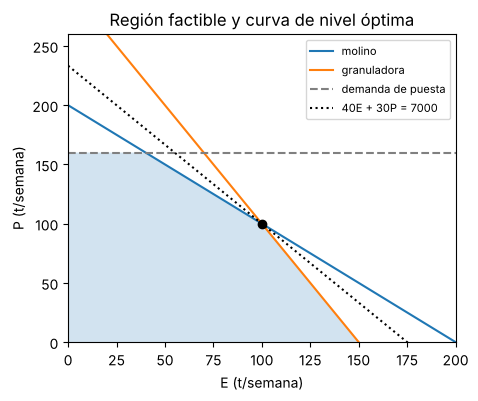

In [5]:
E = np.linspace(0, 200, 400)
plt.figure(figsize=(5, 4))
plt.plot(E, 200 - E, label="molino")
plt.plot(E, 300 - 2 * E, label="granuladora")
plt.axhline(160, color="gray", ls="--", label="demanda de puesta")
plt.fill(*vertices[np.argsort(np.arctan2(vertices[:, 1] - 70, vertices[:, 0] - 60))].T, alpha=0.2)
plt.plot(*mejor, "ko"); plt.plot(E, (7000 - 40 * E) / 30, "k:", label="40E + 30P = 7000")
plt.xlim(0, 200); plt.ylim(0, 260); plt.xlabel("E (t/semana)"); plt.ylabel("P (t/semana)"); plt.legend(fontsize=8)
plt.title("Región factible y curva de nivel óptima"); plt.show()

**Ejercicio 2 · precios sombra.** `linprog` con el método HiGHS devuelve en `res.ineqlin.marginals` la derivada del valor óptimo **de la minimización** respecto a cada término independiente. Como aquí se maximiza $40E+30P$ minimizando su opuesto, el precio sombra de cada recurso es el opuesto del marginal. Guarda en `precios` los tres precios sombra (€/h, €/h, €/t).

In [6]:
# TU CÓDIGO
# --- solución de referencia ---
res = linprog(-c1, A_ub=A1[:3], b_ub=b1[:3], method="highs")
precios = -res.ineqlin.marginals
# --- fin ---

In [7]:
# Comprobación
assert np.allclose(precios, [40, 100 / 3, 0], atol=1e-6)
assert np.isclose(precios @ b1[:3], 7000), "Dualidad fuerte: b·y* = c·x*"
# Una hora más de granuladora vale ~33,33 €:
r2 = linprog(-c1, A_ub=A1[:3], b_ub=b1[:3] + [0, 1, 0], method="highs")
print("Correcto. Precios sombra:", np.round(precios, 4), "· margen con 1 h más de granuladora:", round(-r2.fun, 2))

Correcto. Precios sombra: [40.     33.3333  0.    ] · margen con 1 h más de granuladora: 7033.33


## Parte 2 · Plan de producción semanal de una cervecera (tema 2)

Una cervecera planifica 4 semanas de tres cervezas: *Lager*, *IPA* y *Tostada*. Datos (hL = hectolitros):

* Demanda $d_{pt}$ (hL) en la tabla de abajo; inventario inicial y final nulos.
* Coste variable $c_p$ = 60, 85, 70 €/hL; coste de almacenamiento en frío $h_p$ = 4, 8, 4 €/hL·semana (la IPA pierde aroma: más cara).
* Cada semana que se elabora una cerveza hay un coste de preparación y limpieza $f_p$ = 500 €; si se elabora, el lote mínimo es $L_p$ = 20 hL (un fermentador).
* Capacidad de fermentación $C$ = 280 hL/semana.

Variables: producción $x_{pt}\ge 0$, inventario $I_{pt}\ge 0$ y $y_{pt}\in\{0,1\}$ (se elabora o no). Modelo:

$$\min\sum_{p,t}\bigl(c_p x_{pt}+h_p I_{pt}+f_p y_{pt}\bigr)\quad\text{s.a.}\quad I_{p,t-1}+x_{pt}-I_{pt}=d_{pt},\ \ \sum_p x_{pt}\le C,\ \ L_p y_{pt}\le x_{pt}\le M_{pt}\,y_{pt}.$$

con $M_{pt}=\min\bigl(C,\sum_{s\ge t}d_{ps}\bigr)$, la menor cota válida (ejercicio 2.7 de los apuntes).

In [8]:
productos = ["Lager", "IPA", "Tostada"]
d = np.array([[120, 140, 160, 190],
              [ 60,  50,  80, 100],
              [ 40,  50,  30,  60]], float)
c = np.array([60, 85, 70.]); h = np.array([4, 8, 4.]); f = np.array([500, 500, 500.])
Lmin = np.array([20, 20, 20.]); C = 280.
nP, T = d.shape
n = 3 * nP * T                       # variables: x (12), I (12), y (12)
def ix(k, p, t):                     # k = 0 producción, 1 inventario, 2 binaria
    return k * nP * T + p * T + t
coste = np.concatenate([np.repeat(c, T), np.repeat(h, T), np.repeat(f, T)])
print("Demanda total por semana:", d.sum(0), "· capacidad:", C)

Demanda total por semana: [220. 240. 270. 350.] · capacidad: 280.0


**Ejercicio 3.** Construye las filas de las restricciones de **balance de inventario** $I_{p,t-1}+x_{pt}-I_{pt}=d_{pt}$ (con $I_{p,-1}=0$): una lista `filas_bal` de 12 vectores de longitud `n` y la lista `rhs_bal` con las demandas. Usa `ix`.

In [9]:
# TU CÓDIGO
# --- solución de referencia ---
filas_bal, rhs_bal = [], []
for p in range(nP):
    for t in range(T):
        r = np.zeros(n)
        r[ix(0, p, t)] = 1
        r[ix(1, p, t)] = -1
        if t > 0:
            r[ix(1, p, t - 1)] = 1
        filas_bal.append(r); rhs_bal.append(d[p, t])
# --- fin ---

In [10]:
# Comprobación
assert len(filas_bal) == 12 and np.allclose(rhs_bal, d.ravel())
assert filas_bal[1][ix(1, 0, 0)] == 1 and filas_bal[1][ix(1, 0, 1)] == -1 and filas_bal[1][ix(0, 0, 1)] == 1
print("Correcto: 12 ecuaciones de balance")

Correcto: 12 ecuaciones de balance


In [11]:
filas, lo, hi = list(filas_bal), list(rhs_bal), list(rhs_bal)
for t in range(T):                                   # capacidad
    r = np.zeros(n); r[[ix(0, p, t) for p in range(nP)]] = 1
    filas.append(r); lo.append(-np.inf); hi.append(C)
for p in range(nP):                                  # enlace x-y: L y <= x <= M y
    for t in range(T):
        M = min(C, d[p, t:].sum())
        r = np.zeros(n); r[ix(0, p, t)] = 1; r[ix(2, p, t)] = -M
        filas.append(r); lo.append(-np.inf); hi.append(0)
        r = np.zeros(n); r[ix(0, p, t)] = 1; r[ix(2, p, t)] = -Lmin[p]
        filas.append(r); lo.append(0); hi.append(np.inf)
A2 = np.array(filas); restr = LinearConstraint(A2, lo, hi)
ent = np.r_[np.zeros(2 * nP * T), np.ones(nP * T)]
cotas = Bounds(np.zeros(n), np.r_[np.full(2 * nP * T, np.inf), np.ones(nP * T)])

t0 = time.time()
sol = milp(coste, constraints=restr, integrality=ent, bounds=cotas)       # HiGHS: ramificación y acotación
rel = milp(coste, constraints=restr, bounds=cotas)                         # relajación lineal
x = sol.x[:nP*T].reshape(nP, T); I = sol.x[nP*T:2*nP*T].reshape(nP, T); y = sol.x[2*nP*T:].reshape(nP, T)
print(f"Coste óptimo MILP: {eur(sol.fun)} €   ({time.time() - t0:.2f} s)")
print(f"Relajación lineal: {eur(rel.fun, 2)} €   · gap de integralidad = {eur(100 * (sol.fun - rel.fun) / sol.fun, 2)} %")
for p in range(nP):
    print(f"{productos[p]:8s} x = {x[p].round(1) + 0.0}  I = {I[p].round(1) + 0.0}  y = {y[p].round().astype(int)}")
print("Desglose: variable", (c[:, None] * x).sum(), "· almacén", (h[:, None] * I).sum(), "· preparaciones", (f[:, None] * y).sum())

Coste óptimo MILP: 79.390 €   (0.07 s)
Relajación lineal: 77.284,36 €   · gap de integralidad = 2,65 %
Lager    x = [120. 140. 170. 180.]  I = [ 0.  0. 10.  0.]  y = [1 1 1 1]
IPA      x = [110.   0.  80. 100.]  I = [50.  0.  0.  0.]  y = [1 0 1 1]
Tostada  x = [ 40. 140.   0.   0.]  I = [ 0. 90. 60.  0.]  y = [1 1 0 0]
Desglose: variable 73850.0 · almacén 1040.0 · preparaciones 4500.0


**Ejercicio 4 · precios sombra en un MILP.** Un MILP no tiene dual en sentido estricto. La práctica habitual es **fijar las binarias** en su valor óptimo, resolver el PL resultante y leer sus multiplicadores. Hazlo con `linprog` y guarda en `precio_cap` los 4 precios sombra de la capacidad (€/hL, en valor absoluto: lo que se ahorraría con 1 hL más de fermentación esa semana).

In [12]:
# TU CÓDIGO
# --- solución de referencia ---
yfix = np.round(y.ravel())
bnd = [(0, None)] * (2 * nP * T) + [(v, v) for v in yfix]
Aeq, beq = A2[:12], np.array(lo[:12])
Aub = np.vstack([A2[12:16], A2[16::2], -A2[17::2]])
bub = np.r_[hi[12:16], hi[16::2], -np.array(lo[17::2])]
fij = linprog(coste, A_ub=Aub, b_ub=bub, A_eq=Aeq, b_eq=beq, bounds=bnd, method="highs")
precio_cap = -fij.ineqlin.marginals[:4]
# --- fin ---

In [13]:
# Comprobación
assert np.isclose(fij.fun, sol.fun), "Con las binarias fijas, el PL debe dar el mismo coste"
assert np.allclose(precio_cap, [0, 0, 0, 4], atol=1e-6)
print("Correcto. Precio sombra de la capacidad por semana (€/hL):", precio_cap.round(3))
print("Interpretación: 1 hL más en la semana 4 evita guardar 1 hL una semana (4 €/hL).")
# El precio sombra es local: se comprueba resolviendo de nuevo con más capacidad en la semana 4
for C4 in (281, 290, 300):
    hi2 = list(hi); hi2[15] = C4
    # (la cota big-M de la semana 4 es la demanda pendiente, menor que C, así que no cambia)
    s2 = milp(coste, constraints=LinearConstraint(A2, lo, hi2), integrality=ent, bounds=cotas)
    print(f"  capacidad semana 4 = {C4} hL → coste {eur(s2.fun)} €  (ahorro {eur(sol.fun - s2.fun)} €)")

Correcto. Precio sombra de la capacidad por semana (€/hL): [0. 0. 0. 4.]
Interpretación: 1 hL más en la semana 4 evita guardar 1 hL una semana (4 €/hL).


  capacidad semana 4 = 281 hL → coste 79.386 €  (ahorro 4 €)


  capacidad semana 4 = 290 hL → coste 79.350 €  (ahorro 40 €)
  capacidad semana 4 = 300 hL → coste 79.350 €  (ahorro 40 €)


**Ramificación y acotación a mano.** El solver hace esto con muchas mejoras (preproceso, cortes, heurísticas). Implementamos la versión básica en profundidad y la probamos con el ejercicio 2.4 de los apuntes (adaptado de Bradley, Hax y Magnanti, cap. 9, ej. 10): $\max x_1+5x_2$ s.a. $-4x_1+3x_2\le 6$, $3x_1+2x_2\le 18$, $x\in\mathbb Z_{\ge 0}^2$.

**Ejercicio 5.** Completa `ramifica_y_acota`: resuelve la relajación del nodo, poda si es infactible o si su cota no supera al incumbente, actualiza el incumbente si la solución es entera y, si no, crea dos hijos con $x_i\le\lfloor x_i^*\rfloor$ y $x_i\ge\lceil x_i^*\rceil$ (ramifica en la última variable fraccionaria).

In [14]:
def ramifica_y_acota(cv, A, b, verbose=True):
    pila = [[(0, None)] * len(cv)]
    incumbente, x_inc, nodos = -np.inf, None, 0
    while pila:
        cot = pila.pop(); nodos += 1
        # TU CÓDIGO
        # --- solución de referencia ---
        r = linprog(-np.array(cv), A_ub=A, b_ub=b, bounds=cot, method="highs")
        if r.status != 0:
            continue
        z = -r.fun
        if z <= incumbente + 1e-9:
            continue
        frac = [i for i in range(len(cv)) if abs(r.x[i] - round(r.x[i])) > 1e-7]
        if not frac:
            incumbente, x_inc = z, np.round(r.x)
            if verbose: print(f"  nodo {nodos}: nuevo incumbente {x_inc} con z = {z:g}")
            continue
        i = frac[-1]; a, bb = cot[i]
        izq = list(cot); izq[i] = (a, math.floor(r.x[i]))
        der = list(cot); der[i] = (math.ceil(r.x[i]), bb)
        pila += [izq, der]
        # --- fin ---
    return incumbente, x_inc, nodos

In [15]:
# Comprobación
z, xs, nodos = ramifica_y_acota([1, 5], [[-4, 3], [3, 2]], [6, 18])
assert z == 23 and np.allclose(xs, [3, 4])
print(f"Correcto: óptimo entero {xs} con z = {z:g} tras {nodos} nodos (relajación en la raíz: 28,94)")

  nodo 7: nuevo incumbente [4. 3.] con z = 19
  nodo 8: nuevo incumbente [3. 4.] con z = 23
Correcto: óptimo entero [3. 4.] con z = 23 tras 11 nodos (relajación en la raíz: 28,94)


## Parte 3 · Problemas combinatorios (tema 3)

### 3a · Reparto con ventanas horarias (VRPTW)

El almacén de la cervecera (nodo 0) abastece a 8 bares con 2 furgonetas de 22 barriles. Las distancias son de tipo Manhattan (callejero) en km y la velocidad media es de 30 km/h, es decir, 2 min/km. Cada descarga dura 10 min. Los tiempos se miden en minutos desde las 8:00 y el almacén cierra a los 300 min (13:00).

In [16]:
xy = np.array([[0, 0], [2, 6], [5, 4], [6, -1], [3, -5], [-2, -6], [-5, -2], [-6, 3], [-3, 5]], float)  # km
q = np.array([0, 4, 6, 5, 3, 7, 4, 5, 6])                       # barriles
ventana = [(0, 300), (60, 120), (0, 90), (120, 180), (30, 120), (150, 240), (0, 90), (60, 150), (150, 210)]
servicio, Q, K = 10, 22, 2

**Ejercicio 6.** Calcula la matriz `tt` de tiempos de viaje en minutos enteros: distancia Manhattan (km) × 2 min/km, redondeada.

In [17]:
# TU CÓDIGO
# --- solución de referencia ---
tt = np.round(2 * np.abs(xy[:, None, :] - xy[None, :, :]).sum(-1)).astype(int)
# --- fin ---

In [18]:
# Comprobación
assert tt.shape == (9, 9) and tt[0, 1] == 16 and tt[1, 2] == 10 and tt[4, 7] == 34 and (tt == tt.T).all()
print("Correcto. Tiempos desde el almacén:", tt[0])

Correcto. Tiempos desde el almacén: [ 0 16 18 14 16 16 14 18 16]


**Ejercicio 7 · comprobador de rutas.** Escribe `evalua_ruta(ruta)` para una ruta `[0, i1, ..., ik, 0]`: devuelve `(factible, tiempo_viaje, llegadas)`, donde la llegada a cada nodo es $\max(a_j,\ \text{salida anterior}+t_{ij})$ (se espera si se llega antes de abrir), la ruta es factible si toda llegada es $\le b_j$, el regreso es $\le 300$ y la carga no supera $Q$. El tiempo de viaje es la suma de los $t_{ij}$ (sin esperas ni descargas).

In [19]:
def evalua_ruta(ruta):
    # TU CÓDIGO
    # --- solución de referencia ---
    t, viaje, llegadas, ok = 0, 0, [], q[ruta].sum() <= Q
    for i, j in zip(ruta[:-1], ruta[1:]):
        salida = t + (servicio if i != 0 else 0)
        t = max(ventana[j][0], salida + tt[i, j])
        viaje += tt[i, j]; llegadas.append(int(t))
        ok &= t <= ventana[j][1]
    return bool(ok), int(viaje), llegadas
    # --- fin ---

In [20]:
# Comprobación
ok, v, lleg = evalua_ruta([0, 1, 2, 4, 3, 0])
assert ok and v == 76 and lleg == [60, 80, 112, 136, 160]
assert not evalua_ruta([0, 3, 1, 0])[0], "El bar 1 cierra a los 120 min"
print("Correcto. Llegadas de la ruta 0-1-2-4-3-0:", lleg)

Correcto. Llegadas de la ruta 0-1-2-4-3-0: [60, 80, 112, 136, 160]


**Óptimo exacto por programación dinámica.** Con 8 clientes se puede resolver el problema de forma exacta: para cada subconjunto $S$ de clientes y último cliente $j$ se guardan las etiquetas no dominadas (hora de llegada, tiempo de viaje). Después se combinan dos rutas con conjuntos complementarios. Es el mismo principio que los algoritmos exactos de etiquetado, viable solo para instancias pequeñas.

In [21]:
def vrptw_exacto():
    nn = len(xy); etiquetas = {}
    for j in range(1, nn):
        a = max(ventana[j][0], tt[0, j])
        if a <= ventana[j][1]:
            etiquetas[(1 << j, j)] = [(a, tt[0, j])]
    mejor_ruta = {}
    for S in sorted(range(1 << nn), key=lambda s: bin(s).count("1")):
        carga = sum(q[i] for i in range(nn) if S >> i & 1)
        for j in range(1, nn):
            for (t, cst) in etiquetas.get((S, j), []):
                if t + servicio + tt[j, 0] <= ventana[0][1] and cst + tt[j, 0] < mejor_ruta.get(S, np.inf):
                    mejor_ruta[S] = cst + tt[j, 0]
                for k in range(1, nn):
                    if S >> k & 1 or carga + q[k] > Q:
                        continue
                    a = max(ventana[k][0], t + servicio + tt[j, k])
                    if a > ventana[k][1]:
                        continue
                    nueva, lista = (a, cst + tt[j, k]), etiquetas.setdefault((S | 1 << k, k), [])
                    if any(t2 <= nueva[0] and c2 <= nueva[1] for t2, c2 in lista):
                        continue
                    lista[:] = [e for e in lista if not (nueva[0] <= e[0] and nueva[1] <= e[1])] + [nueva]
    todos = sum(1 << j for j in range(1, nn)); mejor = (np.inf, None)
    for S, v in mejor_ruta.items():
        R = todos ^ S
        if R in mejor_ruta and v + mejor_ruta[R] < mejor[0]:
            mejor = (v + mejor_ruta[R], (S, R))
    return mejor[0], [[i for i in range(1, nn) if s >> i & 1] for s in mejor[1]]

t0 = time.time(); v_opt, grupos = vrptw_exacto()
print(f"Óptimo exacto: {v_opt} min de viaje; clientes por furgoneta: {grupos} ({time.time() - t0:.1f} s)")

Óptimo exacto: 152 min de viaje; clientes por furgoneta: [[1, 2, 3, 4], [5, 6, 7, 8]] (0.0 s)


In [22]:
if HAY_ORTOOLS:
    man = pywrapcp.RoutingIndexManager(len(xy), K, 0); rt = pywrapcp.RoutingModel(man)
    cb = rt.RegisterTransitCallback(lambda i, j: int(tt[man.IndexToNode(i), man.IndexToNode(j)]))
    rt.SetArcCostEvaluatorOfAllVehicles(cb)                  # objetivo: minutos de viaje
    tcb = rt.RegisterTransitCallback(lambda i, j: int(tt[man.IndexToNode(i), man.IndexToNode(j)]
                                                      + (servicio if man.IndexToNode(i) != 0 else 0)))
    rt.AddDimension(tcb, 120, 300, False, "Tiempo")           # espera máx. 120 min, horizonte 300
    dim = rt.GetDimensionOrDie("Tiempo")
    for nodo in range(1, len(xy)):
        dim.CumulVar(man.NodeToIndex(nodo)).SetRange(*ventana[nodo])
    dcb = rt.RegisterUnaryTransitCallback(lambda i: int(q[man.IndexToNode(i)]))
    rt.AddDimensionWithVehicleCapacity(dcb, 0, [Q] * K, True, "Carga")
    prm = pywrapcp.DefaultRoutingSearchParameters()
    prm.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    prm.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    prm.time_limit.seconds = 2
    s_or = rt.SolveWithParameters(prm)
    rutas = []
    for v in range(K):
        i, r = rt.Start(v), []
        while not rt.IsEnd(i):
            r.append(man.IndexToNode(i)); i = s_or.Value(rt.NextVar(i))
        rutas.append(r + [0])
    print("OR-Tools:", s_or.ObjectiveValue(), "min ·", rutas)
else:   # alternativa sin OR-Tools: las rutas óptimas por fuerza bruta dentro de cada grupo
    rutas = []
    for g in grupos:
        cand = [[0, *pp, 0] for pp in itertools.permutations(g)]
        rutas.append(min((r for r in cand if evalua_ruta(r)[0]), key=lambda r: evalua_ruta(r)[1]))
    print("Sin OR-Tools; rutas óptimas por enumeración:", rutas)
tot = sum(evalua_ruta(r)[1] for r in rutas)
assert tot == v_opt == 152 and all(evalua_ruta(r)[0] for r in rutas)
for r in rutas:
    print(r, "llegadas", evalua_ruta(r)[2], "carga", q[r].sum())

OR-Tools: 152 min · [[0, 1, 2, 4, 3, 0], [0, 6, 7, 8, 5, 0]]
[0, 1, 2, 4, 3, 0] llegadas [60, 80, 112, 136, 160] carga 18
[0, 6, 7, 8, 5, 0] llegadas [14, 60, 150, 184, 210] carga 22


### 3b · Planificación de un taller (*job-shop*)

Cuatro pedidos pasan por torno (0), fresadora (1) y taladro (2) en un orden fijo; duraciones en horas. Se minimiza el *makespan* (instante en que acaba el último pedido).

In [23]:
pedidos = [[(0, 3), (1, 2), (2, 2)],
           [(1, 4), (0, 2), (2, 1)],
           [(2, 3), (0, 3), (1, 2)],
           [(0, 2), (2, 3), (1, 3)]]
nm = 3

**Ejercicio 8 · cota inferior.** Ningún programa puede acabar antes que la carga total de la máquina más cargada ni antes que la duración del pedido más largo. Calcula `cota = max(carga máxima, pedido más largo)`.

In [24]:
# TU CÓDIGO
# --- solución de referencia ---
carga = [sum(dd for pd in pedidos for (m, dd) in pd if m == mm) for mm in range(nm)]
cota = max(max(carga), max(sum(dd for _, dd in pd) for pd in pedidos))
# --- fin ---

In [25]:
# Comprobación
assert cota == 11
print("Correcto. Carga por máquina:", carga, "→ cota inferior", cota, "h")

Correcto. Carga por máquina: [10, 11, 9] → cota inferior 11 h


In [26]:
def programa(orden):
    # Programa semiactivo (cada operación lo antes posible) para un orden de pedidos en cada máquina.
    sig = [0] * len(pedidos); fin_p = [0] * len(pedidos); fin_m = [0] * nm; pos = [0] * nm; ini = {}
    for _ in range(sum(map(len, pedidos))):
        for m in range(nm):
            if pos[m] < len(orden[m]):
                j = orden[m][pos[m]]
                if sig[j] < len(pedidos[j]) and pedidos[j][sig[j]][0] == m:
                    st = max(fin_p[j], fin_m[m]); ini[j, sig[j]] = st
                    fin_p[j] = fin_m[m] = st + pedidos[j][sig[j]][1]; sig[j] += 1; pos[m] += 1
                    break
        else:
            return None, None          # orden incompatible con las precedencias (bloqueo)
    return max(fin_p), ini

t0 = time.time()
ordenes = [list(itertools.permutations(range(4)))] * nm
mejor = min((programa(o)[0], o) for o in itertools.product(*ordenes) if programa(o)[0] is not None)
print(f"Enumeración de {24**3} órdenes: makespan óptimo = {mejor[0]} h ({time.time() - t0:.1f} s)")

if HAY_ORTOOLS:
    md_ = cp_model.CpModel(); H = sum(dd for pd in pedidos for _, dd in pd)
    S, Fin, porm = {}, {}, {m: [] for m in range(nm)}
    for j, pd in enumerate(pedidos):
        for k, (m, dd) in enumerate(pd):
            S[j, k] = md_.NewIntVar(0, H, f"s{j}{k}"); Fin[j, k] = md_.NewIntVar(0, H, f"e{j}{k}")
            porm[m].append(md_.NewIntervalVar(S[j, k], dd, Fin[j, k], f"i{j}{k}"))
            if k:
                md_.Add(S[j, k] >= Fin[j, k - 1])            # precedencia dentro del pedido
    for m in porm:
        md_.AddNoOverlap(porm[m])                            # una operación a la vez por máquina
    mk = md_.NewIntVar(0, H, "makespan"); md_.AddMaxEquality(mk, [Fin[j, len(pd) - 1] for j, pd in enumerate(pedidos)])
    md_.Minimize(mk); sv = cp_model.CpSolver(); sv.parameters.num_workers = 1
    print("CP-SAT:", sv.StatusName(sv.Solve(md_)), "makespan =", sv.Value(mk), "h")
    assert sv.Value(mk) == mejor[0]
assert mejor[0] == 12

Enumeración de 13824 órdenes: makespan óptimo = 12 h (0.1 s)
CP-SAT: OPTIMAL makespan = 12 h


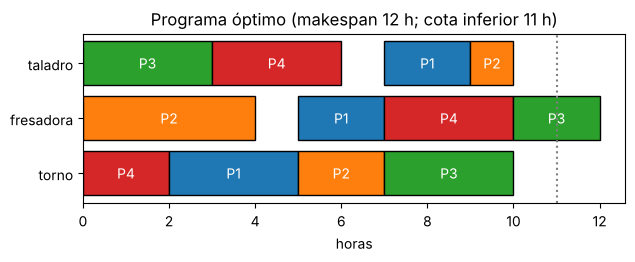

In [27]:
_, ini = programa(mejor[1]); nombres = ["torno", "fresadora", "taladro"]
fig, ax = plt.subplots(figsize=(7, 2.2))
for (j, k), st in ini.items():
    m, dd = pedidos[j][k]
    ax.barh(m, dd, left=st, color=f"C{j}", edgecolor="k"); ax.text(st + dd / 2, m, f"P{j+1}", ha="center", va="center", color="w")
ax.set_yticks(range(nm)); ax.set_yticklabels(nombres); ax.set_xlabel("horas"); ax.axvline(11, ls=":", c="gray")
ax.set_title("Programa óptimo (makespan 12 h; cota inferior 11 h)"); plt.show()

## Parte 4 · Despacho económico (tema 4)

Tres grupos térmicos cubren una demanda de $D=850$ MW. El coste horario de cada uno es $C_i(P_i)=a_i+b_iP_i+c_iP_i^2$ (€/h) con límites técnicos $P_i^{\min}\le P_i\le P_i^{\max}$. Las condiciones KKT dicen que en el óptimo todos los grupos que no están en un límite tienen el **mismo coste incremental** $b_i+2c_iP_i=\lambda$, y $\lambda$ es el precio marginal de la energía (€/MWh).

In [28]:
a4 = np.array([500, 400, 300.]); b4 = np.array([18, 20, 26.]); c4 = np.array([0.02, 0.01, 0.005])
Pmin = np.array([100, 50, 50.]); Pmax = np.array([400, 350, 300.]); D = 850.
coste4 = lambda P: float(np.sum(a4 + b4 * P + c4 * P**2))

**Ejercicio 9 · búsqueda de λ.** Para un $\lambda$ dado, cada grupo produce $P_i(\lambda)=\mathrm{clip}\bigl((\lambda-b_i)/(2c_i),\ P_i^{\min},\ P_i^{\max}\bigr)$, que es creciente en $\lambda$. Encuentra por bisección el $\lambda$ con $\sum_i P_i(\lambda)=D$ y guarda `lam` y `P_opt`.

In [29]:
def potencias(lam):
    return np.clip((lam - b4) / (2 * c4), Pmin, Pmax)
# TU CÓDIGO
# --- solución de referencia ---
lo_, hi_ = 0.0, 100.0
for _ in range(100):
    lam = 0.5 * (lo_ + hi_)
    if potencias(lam).sum() < D:
        lo_ = lam
    else:
        hi_ = lam
P_opt = potencias(lam)
# --- fin ---

In [30]:
# Comprobación
assert abs(lam - 28.4) < 1e-6 and np.allclose(P_opt, [260, 350, 240], atol=1e-4)
print(f"Correcto: λ = {eur(lam, 4)} €/MWh · P = {P_opt.round(2)} MW · coste = {eur(coste4(P_opt))} €/h")
print("Costes incrementales:", (b4 + 2 * c4 * P_opt).round(3), "→ el grupo 2 está en su máximo y su multiplicador es", round(lam - (b4[1] + 2 * c4[1] * 350), 3))

Correcto: λ = 28,4000 €/MWh · P = [260. 350. 240.] MW · coste = 21.985 €/h
Costes incrementales: [28.4 27.  28.4] → el grupo 2 está en su máximo y su multiplicador es 1.4


In [31]:
if HAY_CVXPY:
    P = cp.Variable(3); bal = cp.sum(P) == D
    prob = cp.Problem(cp.Minimize(cp.sum(a4 + cp.multiply(b4, P) + cp.multiply(c4, cp.square(P)))), [bal, P >= Pmin, P <= Pmax])
    prob.solve()
    print("CVXPY:", P.value.round(3), "· coste", round(prob.value, 2), "· multiplicador del balance", round(abs(bal.dual_value), 4))
else:   # alternativa: SLSQP de scipy
    r = minimize(coste4, x0=np.full(3, D / 3), method="SLSQP", bounds=list(zip(Pmin, Pmax)),
                 constraints=[{"type": "eq", "fun": lambda P: P.sum() - D}])
    print("SLSQP:", r.x.round(3), "· coste", round(r.fun, 2))
# Sensibilidad: el coste de 10 MW más se estima con λ y se compara con el valor exacto
lam2 = lam; Ps = []
for Dx in (D, D + 10):
    lo_, hi_ = 0.0, 100.0
    for _ in range(100):
        m_ = 0.5 * (lo_ + hi_); lo_, hi_ = (m_, hi_) if potencias(m_).sum() < Dx else (lo_, m_)
    Ps.append(coste4(potencias(m_)))
print(f"+10 MW: estimación λ·ΔD = {10 * lam2:.1f} €/h · exacto = {Ps[1] - Ps[0]:.1f} €/h")

CVXPY: [260. 350. 240.] · coste 21985.0 · multiplicador del balance 28.4
+10 MW: estimación λ·ΔD = 284.0 €/h · exacto = 284.4 €/h


## Parte 5 · Distribución en planta: metaheurísticas y multiobjetivo (tema 5)

Seis departamentos (Recepción, Almacén, Mecanizado, Soldadura, Pintura, Expedición) se asignan a seis naves en una cuadrícula de 2×3 con centros a 20 m. Objetivo 1: **recorrido de carretillas** $f_1=\sum_{i<j}F_{ij}\,d_{\pi(i)\pi(j)}$ (m/día), con $F$ los viajes diarios y $d$ la distancia Manhattan. Objetivo 2: **riesgo por proximidad** de pares incompatibles, $f_2=\sum w_{ij}\cdot 20/d_{\pi(i)\pi(j)}$ (soldadura–pintura: chispas y disolventes; mecanizado–pintura: polvo; soldadura–almacén). Es un problema cuadrático de asignación: $6!=720$ distribuciones, de modo que podemos comprobar todo por enumeración.

In [32]:
dptos = ["R", "A", "M", "S", "P", "E"]
F5 = np.array([[ 0, 30,  0,  0,  0,  0],
               [30,  0, 25, 10,  0,  5],
               [ 0, 25,  0, 20,  5,  0],
               [ 0, 10, 20,  0, 25,  0],
               [ 0,  0,  5, 25,  0, 30],
               [ 0,  5,  0,  0, 30,  0]])
naves = np.array([[0, 0], [20, 0], [40, 0], [0, 20], [20, 20], [40, 20]])
Dn = np.abs(naves[:, None] - naves[None]).sum(-1)
W5 = np.zeros((6, 6))
for i, j, w in [(3, 4, 10), (2, 4, 4), (3, 1, 3)]:
    W5[i, j] = W5[j, i] = w
def f1(pi): return 0.5 * float((F5 * Dn[np.ix_(pi, pi)]).sum())
def f2(pi):
    dd = Dn[np.ix_(pi, pi)]; m = W5 > 0
    return 0.5 * float((W5[m] * 20 / dd[m]).sum())
todas = list(itertools.permutations(range(6)))
V = np.array([(f1(p), f2(p)) for p in todas])
print("f1 mínimo por enumeración:", V[:, 0].min(), "m/día ·", int((V[:, 0] == V[:, 0].min()).sum()), "distribuciones óptimas (simetrías)")

f1 mínimo por enumeración: 3400.0 m/día · 16 distribuciones óptimas (simetrías)


**Ejercicio 10 · recocido simulado.** Completa la regla de aceptación de Metropolis: se acepta siempre si $\Delta\le 0$ y, si no, con probabilidad $e^{-\Delta/T}$.

In [33]:
def recocido(f, T0=500.0, alfa=0.995, iters=3000, semilla=0):
    rng = np.random.default_rng(semilla)
    pi = list(rng.permutation(6)); actual = f(pi); mejor = (actual, pi[:]); T = T0
    for _ in range(iters):
        i, j = rng.choice(6, 2, replace=False); cand = pi[:]; cand[i], cand[j] = cand[j], cand[i]
        delta = f(cand) - actual
        # TU CÓDIGO: decide si se acepta
        # --- solución de referencia ---
        acepta = delta <= 0 or rng.random() < math.exp(-delta / T)
        # --- fin ---
        if acepta:
            pi, actual = cand, actual + delta
            if actual < mejor[0]:
                mejor = (actual, pi[:])
        T *= alfa
    return mejor

In [34]:
# Comprobación
res_sa = [recocido(f1, semilla=s)[0] for s in range(5)]
assert all(abs(v - 3400) < 1e-9 for v in res_sa), res_sa
mejor_sa = recocido(f1)[1]
print("Correcto: las 5 ejecuciones alcanzan f1 = 3400 m/día. Distribución (nave de cada dpto.):",
      {d_: int(n_) for d_, n_ in zip(dptos, mejor_sa)})

Correcto: las 5 ejecuciones alcanzan f1 = 3400 m/día. Distribución (nave de cada dpto.): {'R': 5, 'A': 2, 'M': 1, 'S': 4, 'P': 3, 'E': 0}


**Ejercicio 11 · frente de Pareto.** Un punto domina a otro si no es peor en ningún objetivo y es mejor en alguno. Escribe `no_dominados(V)` que devuelva los índices de los puntos no dominados (minimizando ambos objetivos).

In [35]:
def no_dominados(V):
    # TU CÓDIGO
    # --- solución de referencia ---
    idx = []
    for i, v in enumerate(V):
        if not np.any(np.all(V <= v, axis=1) & np.any(V < v, axis=1)):
            idx.append(i)
    return np.array(idx)
    # --- fin ---

In [36]:
# Comprobación
nd = no_dominados(V)
frente = np.unique(V[nd].round(6), axis=0)
assert np.allclose(frente, [[3400, 13.5], [3700, 10.5], [3900, 47 / 6], [4400, 41 / 6]])
# ¿Qué puntos alcanza la suma ponderada?
apoyados = {tuple(float(v) for v in V[np.argmin(w * V[:, 0] / 4400 + (1 - w) * V[:, 1] / 13.5)].round(4)) for w in np.linspace(0, 1, 2001)}
print("Correcto. Frente de Pareto:\n", frente.round(3))
print("Puntos alcanzables con suma ponderada:", sorted(apoyados))

Correcto. Frente de Pareto:
 [[3400.      13.5  ]
 [3700.      10.5  ]
 [3900.       7.833]
 [4400.       6.833]]
Puntos alcanzables con suma ponderada: [(3400.0, 13.5), (3900.0, 7.8333), (4400.0, 6.8333)]


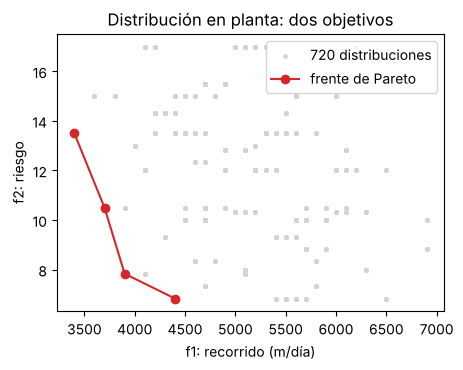

In [37]:
plt.figure(figsize=(5, 3.6))
plt.scatter(V[:, 0], V[:, 1], s=6, c="lightgray", label="720 distribuciones")
plt.plot(frente[:, 0], frente[:, 1], "o-", c="C3", label="frente de Pareto")
plt.xlabel("f1: recorrido (m/día)"); plt.ylabel("f2: riesgo"); plt.legend(); plt.title("Distribución en planta: dos objetivos"); plt.show()

**NSGA-II mínimo.** Con 720 soluciones la enumeración basta, pero en problemas reales no. El NSGA-II (Deb *et al.*, 2002) mantiene una población, la ordena por frentes no dominados y, dentro de cada frente, prefiere las soluciones aisladas (distancia de *crowding*). Aquí, con cruce por orden (OX) y mutación por intercambio.

In [38]:
def ordenacion_no_dominada(V):
    rangos = np.full(len(V), -1); restantes = np.arange(len(V)); r = 0
    while len(restantes):
        nd_ = restantes[no_dominados(V[restantes])]; rangos[nd_] = r
        restantes = np.setdiff1d(restantes, nd_); r += 1
    return rangos
def crowding(V):
    n_ = len(V); dist = np.zeros(n_)
    for k in range(V.shape[1]):
        o = np.argsort(V[:, k]); rango = V[o[-1], k] - V[o[0], k] or 1.0
        dist[o[0]] = dist[o[-1]] = np.inf
        dist[o[1:-1]] += (V[o[2:], k] - V[o[:-2], k]) / rango
    return dist
def cruce_ox(p1, p2, rng):
    i, j = sorted(rng.choice(6, 2, replace=False)); hijo = [None] * 6; hijo[i:j + 1] = p1[i:j + 1]
    resto = [g for g in p2 if g not in hijo]
    for k in range(6):
        if hijo[k] is None:
            hijo[k] = resto.pop(0)
    return hijo
def nsga2(N=40, generaciones=40, semilla=1):
    rng = np.random.default_rng(semilla); evalua = lambda pp: np.array([(f1(p), f2(p)) for p in pp])
    pob = [list(rng.permutation(6)) for _ in range(N)]
    for _ in range(generaciones):
        Vp = evalua(pob); rk = ordenacion_no_dominada(Vp); cw = np.zeros(N)
        for r in np.unique(rk):
            cw[rk == r] = crowding(Vp[rk == r])
        def torneo():
            i, j = rng.choice(N, 2, replace=False)
            return pob[i] if (rk[i], -cw[i]) < (rk[j], -cw[j]) else pob[j]
        hijos = []
        for _ in range(N):
            h_ = cruce_ox(torneo(), torneo(), rng)
            if rng.random() < 0.3:
                i, j = rng.choice(6, 2, replace=False); h_[i], h_[j] = h_[j], h_[i]
            hijos.append(h_)
        union = pob + hijos; Vu = evalua(union); rk = ordenacion_no_dominada(Vu); nueva = []
        for r in np.unique(rk):
            fr = np.where(rk == r)[0]
            if len(nueva) + len(fr) <= N:
                nueva += list(fr)
            else:
                cw = crowding(Vu[fr]); nueva += list(fr[np.argsort(-cw)[:N - len(nueva)]]); break
        pob = [union[i] for i in nueva]
    Vp = evalua(pob)
    return np.unique(Vp[no_dominados(Vp)].round(6), axis=0)
t0 = time.time(); fr_nsga = nsga2()
print(f"NSGA-II ({time.time() - t0:.1f} s) encuentra:\n", fr_nsga.round(3))
print("¿Recupera el frente exacto?", np.allclose(fr_nsga, frente))

NSGA-II (0.3 s) encuentra:
 [[3400.      13.5  ]
 [3700.      10.5  ]
 [3900.       7.833]
 [4400.       6.833]]
¿Recupera el frente exacto? True


## Parte 6 · Predecir y después optimizar: cerveza fresca (tema 6)

La cervecera vende dos cervezas **sin pasteurizar** (IPA y Lager) que caducan en una semana. Cada lunes decide cuánto envasar, $q=(q_1,q_2)$ en hL, con una capacidad conjunta de $K=260$ hL. Lo que no se vende se liquida a precio de saldo. Por hL: precio $p=(300,220)$, coste $c=(70,60)$, saldo $s=(20,10)$ €. La demanda depende de la temperatura media de la semana, de si hay festivo y de una tendencia, con ruido multiplicativo log-normal correlacionado entre ambas cervezas.

Protocolo temporal **sin fugas**: semanas 0–103 para entrenar el modelo de predicción, 104–155 para calibrar la incertidumbre (residuos fuera de muestra) y 156–207 como prueba, donde se simula la operación.

In [39]:
rng = np.random.default_rng(24)
Wk = 208; sem = np.arange(Wk); semana_año = sem % 52
temp = 17 + 8 * np.sin(2 * np.pi * (semana_año - 13) / 52) + rng.normal(0, 2.5, Wk)   # ºC
fest = (rng.random(Wk) < 0.15).astype(float)
sig = 0.22
base = np.stack([np.exp(np.log(30) + 0.045 * temp + 0.25 * fest + 0.0015 * sem),
                 np.exp(np.log(45) + 0.040 * temp + 0.20 * fest + 0.0010 * sem)], 1)
ruido = rng.multivariate_normal([0, 0], [[sig**2, 0.5 * sig**2], [0.5 * sig**2, sig**2]], Wk)
Dem = base * np.exp(ruido - sig**2 / 2)                      # hL/semana
X6 = np.column_stack([temp, fest, sem])
ent_, cal_, pru_ = sem < 104, (sem >= 104) & (sem < 156), sem >= 156
p6 = np.array([300, 220.]); c6 = np.array([70, 60.]); s6 = np.array([20, 10.]); K6 = 260.
print("Demanda media (hL): entrenamiento", Dem[ent_].mean(0).round(1), "· prueba", Dem[pru_].mean(0).round(1))

Demanda media (hL): entrenamiento [ 72.5 100.1] · prueba [ 91.1 115. ]


In [40]:
modelos = [LinearRegression().fit(X6[ent_], np.log(Dem[ent_, k])) for k in range(2)]
res_cal = np.stack([np.log(Dem[cal_, k]) - modelos[k].predict(X6[cal_]) for k in range(2)], 1)  # residuos fuera de muestra
mu_log = np.stack([modelos[k].predict(X6[pru_]) for k in range(2)], 1)                        # predicción del log
s_hat = res_cal.std(0)
media_pred = np.exp(mu_log + s_hat**2 / 2)
print("Coeficientes (temp, festivo, semana) IPA:", modelos[0].coef_.round(4), "· Lager:", modelos[1].coef_.round(4))
print("Desviación de los residuos de calibración:", s_hat.round(3),
      "· MAPE de la media en prueba:", (np.abs(media_pred - Dem[pru_]) / Dem[pru_]).mean(0).round(3))

Coeficientes (temp, festivo, semana) IPA: [0.0447 0.1917 0.0018] · Lager: [0.0353 0.1704 0.0011]
Desviación de los residuos de calibración: [0.213 0.211] · MAPE de la media en prueba: [0.181 0.209]


**Ejercicio 12 · el vendedor de periódicos.** Si se envasa de menos se pierde $c_u=p-c$ por hL; si se envasa de más, $c_o=c-s$. La cantidad óptima es el cuantil de la demanda de orden $c_u/(c_u+c_o)$ (fractil crítico, demostrado en los apuntes). Calcula `fractil` (vector de 2) y la decisión `qB` = $\exp(\hat\mu+\hat r_{\text{fractil}})$, con $\hat r$ el cuantil empírico de los residuos de calibración de cada cerveza; después aplica `ajusta_capacidad`.

In [41]:
def beneficio(q, Dm):
    vend = np.minimum(q, Dm)
    return (p6 * vend - c6 * q + s6 * (q - vend)).sum(-1)
def ajusta_capacidad(q):          # si se supera K, se reduce en proporción
    tot = q.sum(-1, keepdims=True)
    return np.where(tot > K6, q * K6 / tot, q)
# TU CÓDIGO
# --- solución de referencia ---
cu, co = p6 - c6, c6 - s6
fractil = cu / (cu + co)
qB = ajusta_capacidad(np.exp(mu_log + np.array([np.quantile(res_cal[:, k], fractil[k]) for k in range(2)])))
# --- fin ---

In [42]:
# Comprobación
assert np.allclose(fractil, [230 / 280, 160 / 210])
assert qB.shape == (52, 2) and np.all(qB.sum(1) <= K6 + 1e-9)
print("Correcto. Fractiles críticos:", fractil.round(4), "· producción media:", qB.mean(0).round(1), "hL")

Correcto. Fractiles críticos: [0.8214 0.7619] · producción media: [ 97.5 118.8] hL


**SAA con capacidad.** El cuantil ignora que las dos cervezas compiten por la capacidad. La **aproximación por media muestral** (SAA) resuelve, cada semana, un PL con los 52 escenarios de residuos (conjuntos, que conservan la correlación): maximizar el beneficio medio con variables de venta $v_{ks}\le q_k$, $v_{ks}\le D_{ks}$.

In [43]:
def saa(mu, R):
    S = len(R); nv = 2 + 2 * S
    cst = np.r_[c6 - s6, np.full(S, -(p6[0] - s6[0]) / S), np.full(S, -(p6[1] - s6[1]) / S)]
    A, b = [], []
    for k in range(2):
        for j in range(S):
            r = np.zeros(nv); r[2 + k * S + j] = 1; r[k] = -1; A.append(r); b.append(0)
    A.append(np.r_[1, 1, np.zeros(2 * S)]); b.append(K6)
    cot = [(0, None)] * 2 + [(0, np.exp(mu[0] + R[j, 0])) for j in range(S)] + [(0, np.exp(mu[1] + R[j, 1])) for j in range(S)]
    return linprog(cst, A_ub=np.array(A), b_ub=b, bounds=cot, method="highs").x[:2]

qA = ajusta_capacidad(media_pred)                                    # plan con la predicción puntual
qC = np.array([saa(m, res_cal) for m in mu_log])                     # SAA
qD = ajusta_capacidad(np.exp(mu_log + np.quantile(res_cal, 0.05, axis=0)))   # robusto: peor caso de la caja del 90 %
qP = ajusta_capacidad(Dem[pru_])                                     # información perfecta (cota)
tabla = {}
for nombre, qq in [("A · media predicha", qA), ("B · cuantil (fractil)", qB), ("C · SAA con capacidad", qC),
                   ("D · robusto (caja 90 %)", qD), ("Información perfecta", qP)]:
    bnf = beneficio(qq, Dem[pru_]); tabla[nombre] = bnf
    print(f"{nombre:25s} beneficio medio {eur(bnf.mean()):>7s} €/sem · peor semana {eur(bnf.min()):>7s} € · servicio {(qq >= Dem[pru_]).mean(0).round(2)}")

A · media predicha        beneficio medio  34.145 €/sem · peor semana  16.390 € · servicio [0.56 0.5 ]
B · cuantil (fractil)     beneficio medio  34.595 €/sem · peor semana  15.482 € · servicio [0.75 0.62]
C · SAA con capacidad     beneficio medio  34.615 €/sem · peor semana  15.465 € · servicio [0.77 0.6 ]
D · robusto (caja 90 %)   beneficio medio  26.562 €/sem · peor semana  16.440 € · servicio [0.06 0.08]
Información perfecta      beneficio medio  36.502 €/sem · peor semana  19.105 € · servicio [0.81 0.81]


In [44]:
medias = {k: v.mean() for k, v in tabla.items()}
assert medias["C · SAA con capacidad"] >= medias["B · cuantil (fractil)"] > medias["A · media predicha"] > medias["D · robusto (caja 90 %)"]
assert tabla["D · robusto (caja 90 %)"].min() > tabla["C · SAA con capacidad"].min()
print("Pérdida por usar la media en vez del cuantil:", round(medias["B · cuantil (fractil)"] - medias["A · media predicha"]), "€/semana")
print("Precio de la robustez (SAA − robusto):", round(medias["C · SAA con capacidad"] - medias["D · robusto (caja 90 %)"]), "€/semana")
print("Valor de la información perfecta respecto a SAA:", round(medias["Información perfecta"] - medias["C · SAA con capacidad"]), "€/semana")

Pérdida por usar la media en vez del cuantil: 450 €/semana
Precio de la robustez (SAA − robusto): 8053 €/semana
Valor de la información perfecta respecto a SAA: 1887 €/semana


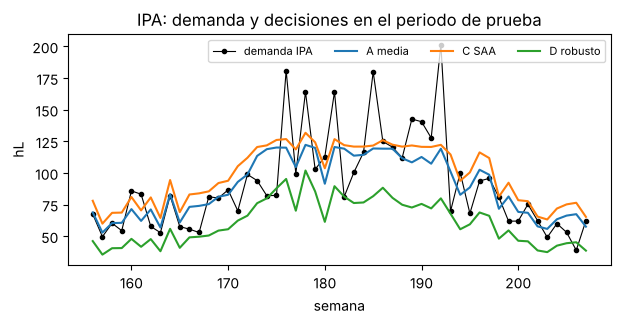

Tiempo total de ejecución: 4.3 s


In [45]:
plt.figure(figsize=(7, 3))
plt.plot(sem[pru_], Dem[pru_, 0], "k.-", lw=0.8, label="demanda IPA")
plt.plot(sem[pru_], qA[:, 0], label="A media"); plt.plot(sem[pru_], qC[:, 0], label="C SAA"); plt.plot(sem[pru_], qD[:, 0], label="D robusto")
plt.xlabel("semana"); plt.ylabel("hL"); plt.legend(fontsize=8, ncol=4); plt.title("IPA: demanda y decisiones en el periodo de prueba"); plt.show()
print(f"Tiempo total de ejecución: {time.time() - T_INICIO:.1f} s")

## Parte 7 · Retos

1. **Cervecera con turnos.** Añade a la parte 2 una variable entera de turnos extra por semana (cada turno añade 40 hL de capacidad y cuesta 900 €). ¿Cuándo compensa?
2. **Ventanas blandas.** En la parte 3a, permite llegar tarde con una penalización de 2 €/min (en OR-Tools: `SetCumulVarSoftUpperBound`). ¿Cuánto baja el tiempo de viaje?
3. **CMA-ES.** Instala `cma` o implementa una estrategia (1+1)-ES con la regla del 1/5 y calibra los dos parámetros $(0{,}045;\ 0{,}25)$ de la demanda de IPA minimizando el error cuadrático del log; compara con la regresión lineal.
4. **Fuga de datos.** En la parte 6 usa los residuos **de entrenamiento** en lugar de los de calibración con un modelo flexible (`GradientBoostingRegressor` con árboles profundos). ¿Qué les pasa a los cuantiles y al nivel de servicio en prueba?
5. **SPO.** Sustituye la regresión de la parte 6 por una que minimice directamente el beneficio perdido en calibración (pérdida de decisión) y compárala.

---
### Comentarios a las soluciones de referencia
Inténtalo antes de leer.

* **Ej. 1.** Con $m$ restricciones en $\mathbb R^2$ hay $\binom{m}{2}$ candidatos; solo los factibles son vértices. Es el algoritmo «de libro» que el símplex evita recorriendo vértices adyacentes con mejora.
* **Ej. 2.** El signo de los marginales depende del convenio del solver: HiGHS da $\partial z_{\min}/\partial b$. Al maximizar con $-c$ hay que cambiar el signo. La restricción de demanda no está activa, así que su precio es 0 (holgura complementaria).
* **Ej. 3.** El índice `ix` evita errores de posición; en un modelador (PuLP, Pyomo, OR-Tools MathOpt) se escriben las restricciones por nombre, que es lo recomendable en proyectos reales.
* **Ej. 4.** Los precios sombra con binarias fijas son locales: valen mientras no cambie el patrón de preparaciones. La capacidad solo está activa en la semana 4 y su valor (4 €/hL) es el coste de adelantar 1 hL una semana.
* **Ej. 5.** Explorar en profundidad encuentra pronto un incumbente; la poda por cota usa que la relajación da una cota superior en cada nodo.
* **Ej. 6–7.** La espera es libre en este modelo, por eso la llegada es $\max(a_j,\ \cdot)$. OR-Tools la representa con la holgura (*slack*) de la dimensión de tiempo.
* **Ej. 8.** La cota de carga (11 h) no es alcanzable aquí: el óptimo es 12 h. Las cotas inferiores sirven para medir la calidad de una heurística.
* **Ej. 9.** La bisección funciona porque $\sum_iP_i(\lambda)$ es continua y no decreciente. Es el método de iteración en $\lambda$ de los libros de sistemas eléctricos.
* **Ej. 10.** Con $T$ grande se acepta casi todo (exploración); con $T$ pequeño solo mejoras (explotación).
* **Ej. 11.** El punto $(3700;\ 10{,}5)$ es Pareto-óptimo pero no lo encuentra ninguna suma ponderada: está por encima del segmento que une sus vecinos (frente no convexo).
* **Ej. 12.** Usar la media equivale a fijar el fractil en ≈ 0,5: con márgenes altos ($c_u\gg c_o$) conviene producir más que la media.